# 05 – EV adoption, income and deprivation

**Business question 3.** How is EV adoption related to income and deprivation?

**Measures used**
- **EV adoption:** the share of privately kept cars that are battery electric, at 30 June 2026 (`bev_private_share`, in %). A share, not a count, so large and small areas can be compared. Private cars only, for the reason explained in notebook 04 (company cars are registered at the lease company's address).
- **Income:** gross disposable household income (GDHI) per head, 2024, in pounds. Available for all 361 local authorities.
- **Deprivation:** the average score of the English Index of Multiple Deprivation 2025 (IMD). **A higher score means more deprived.** England only (296 local authorities).

**Method:** scatter plots, a correlation coefficient and a simple comparison of five deprivation groups. Two coefficients are shown:
- **Pearson** measures how close the points are to a straight line.
- **Spearman** does the same with rankings instead of values, so a few extreme areas (e.g. Kensington and Chelsea, with income of £116,000 per head) cannot drive the result.

If the two are similar, the result is robust. Both go from −1 to +1; around 0.3 is usually called weak, 0.5 moderate and 0.7 or more strong.

**Correlation is not causation.** Richer areas also differ in housing, age and car use. The aim is to describe *where* adoption is high or low, not to prove *why*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. Data

The local analysis table from notebook 04, joined with the deprivation scores.

In [2]:
la = pd.read_csv(PROCESSED + "la_analysis_table.csv")
deprivation = pd.read_csv(PROCESSED + "deprivation_by_la.csv")

# Left join: Scotland, Wales and Northern Ireland have no IMD score (left empty)
la = la.merge(deprivation[["la_code", "imd_score"]], on="la_code", how="left")
la["nation"] = la["la_code"].str[0].map({"E": "England", "W": "Wales", "S": "Scotland", "N": "Northern Ireland"})
la["london"] = la["region"] == "London"

print(la.shape)
la[["bev_private_share", "gdhi_per_head_2024", "imd_score"]].describe().round(1)

(361, 16)


,bev_private_share,gdhi_per_head_2024,imd_score
count,361.0,361.0,296.0
mean,3.1,26504.9,20.1
std,1.0,9411.9,7.9
min,0.7,16786.0,5.9
25%,2.6,21741.0,13.8
50%,3.1,24515.0,19.0
75%,3.7,28102.0,25.5
max,7.8,115641.0,43.5


## 2. EV adoption and income

In [3]:
def correlations(data, x, y="bev_private_share"):
    return pd.Series({
        "Pearson": data[x].corr(data[y]),
        # Spearman = Pearson correlation of the rankings (1st, 2nd, 3rd...) instead of the values
        "Spearman": data[x].rank().corr(data[y].rank()),
        "Local authorities": len(data),
    })

pd.DataFrame({
    "All UK": correlations(la, "gdhi_per_head_2024"),
    "UK excluding London": correlations(la[~la["london"]], "gdhi_per_head_2024"),
}).round(2)

,All UK,UK excluding London
Pearson,0.71,0.63
Spearman,0.69,0.65
Local authorities,361.00,328.00


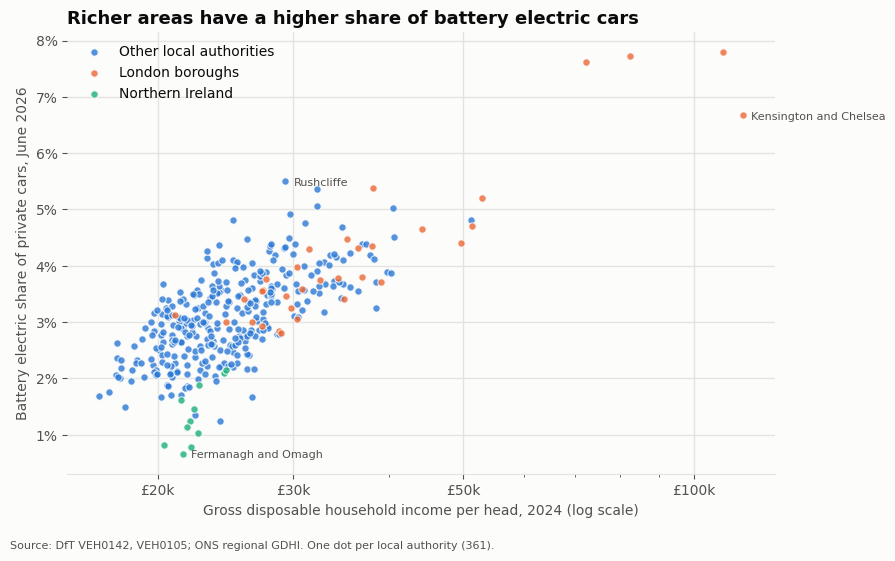

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.6))
groups = [
    ("Other local authorities", ~la["london"] & (la["nation"] != "Northern Ireland"), BLUE),
    ("London boroughs", la["london"], ORANGE),
    ("Northern Ireland", la["nation"] == "Northern Ireland", AQUA),
]
for name, rows, color in groups:
    ax.scatter(la.loc[rows, "gdhi_per_head_2024"], la.loc[rows, "bev_private_share"],
               s=28, color=color, alpha=0.8, edgecolor=SURFACE, linewidth=0.8, label=name)

# Logarithmic scale, so a few very rich central London boroughs do not squeeze all other points to the left
ax.set_xscale("log")
ax.set_xticks([20_000, 30_000, 50_000, 100_000])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v / 1000:.0f}k"))
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=True)
ax.set_axisbelow(True)

for name in ["Kensington and Chelsea", "Rushcliffe", "Fermanagh and Omagh"]:
    row = la[la["la_name"] == name].iloc[0]
    ax.annotate(name, (row["gdhi_per_head_2024"], row["bev_private_share"]), xytext=(6, -3),
                textcoords="offset points", fontsize=8, color=TEXT_2)

ax.set_title("Richer areas have a higher share of battery electric cars")
ax.set_xlabel("Gross disposable household income per head, 2024 (log scale)")
ax.set_ylabel("Battery electric share of private cars, June 2026")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(rect=(0, 0.04, 1, 1))
add_source(fig, "Source: DfT VEH0142, VEH0105; ONS regional GDHI. One dot per local authority (361).")
fig.savefig(FIGURES + "07_bev_share_vs_income.png", dpi=200)
plt.show()

**How to read this chart:** each dot is a local authority. Further right means higher income per head, higher up means a larger share of private cars are battery electric. The income axis is logarithmic: each step (£20k → £30k → £50k) is a similar *percentage* increase.

**What it shows**
- The dots rise from left to right: **richer areas have higher EV adoption.** The correlation is strong (Pearson 0.71, Spearman 0.69) and stays clear without London (0.63 / 0.65).
- **London** (orange) sits at the top right: high incomes and the highest shares.
- **Northern Ireland** (green) sits well below everyone else at similar income levels: 1.4% of private cars, against 3.2% in the rest of the UK. Income alone does not explain this; Northern Ireland has its own, slower EV market.
- Income does not explain everything: among the 50 areas with £24,000–26,000 per head (excluding Northern Ireland), most shares lie between about 2% and 4%.

## 3. EV adoption and deprivation (England)

In [5]:
england = la[la["nation"] == "England"].copy()

pd.DataFrame({
    "England": correlations(england, "imd_score"),
    "England excluding London": correlations(england[~england["london"]], "imd_score"),
}).round(2)

,England,England excluding London
Pearson,-0.55,-0.72
Spearman,-0.67,-0.77
Local authorities,296.00,263.00


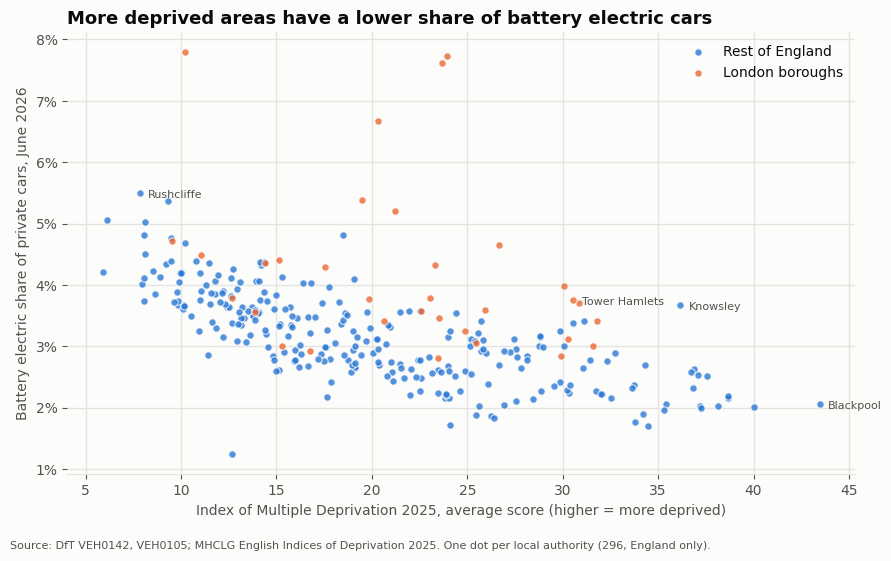

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.6))
for name, rows, color in [("Rest of England", ~england["london"], BLUE), ("London boroughs", england["london"], ORANGE)]:
    ax.scatter(england.loc[rows, "imd_score"], england.loc[rows, "bev_private_share"],
               s=28, color=color, alpha=0.8, edgecolor=SURFACE, linewidth=0.8, label=name)

for name in ["Blackpool", "Knowsley", "Rushcliffe", "Tower Hamlets"]:
    row = england[england["la_name"] == name].iloc[0]
    ax.annotate(name, (row["imd_score"], row["bev_private_share"]), xytext=(6, -3),
                textcoords="offset points", fontsize=8, color=TEXT_2)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=True)
ax.set_axisbelow(True)
ax.set_title("More deprived areas have a lower share of battery electric cars")
ax.set_xlabel("Index of Multiple Deprivation 2025, average score (higher = more deprived)")
ax.set_ylabel("Battery electric share of private cars, June 2026")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(rect=(0, 0.04, 1, 1))
add_source(fig, "Source: DfT VEH0142, VEH0105; MHCLG English Indices of Deprivation 2025. One dot per local authority (296, England only).")
fig.savefig(FIGURES + "08_bev_share_vs_deprivation.png", dpi=200)
plt.show()

**How to read this chart:** each dot is an English local authority. Further right means more deprived.

**What it shows**
- The dots fall from left to right: **more deprived areas have lower EV adoption.** Outside London the link is strong (Pearson −0.72, Spearman −0.77).
- **London is the exception.** Several boroughs are fairly deprived on the IMD but still have high shares (e.g. Tower Hamlets). London mixes very high and very low incomes in the same borough, and its EV owners are likely to be the better-off residents. This is why the overall England coefficient is weaker (Pearson −0.55).
- A few deprived areas outside London, such as Knowsley, have a higher share than expected. The data does not say why, but they show that low adoption is not inevitable.

## 4. Five deprivation groups: adoption and public charging

England's local authorities are split into five equal groups (quintiles) by IMD score, from the least deprived fifth (1) to the most deprived fifth (5). For each group, three things are compared:
- **EV adoption:** battery electric share of private cars.
- **Public charging provision:** public chargers per 100,000 residents.
- **Current pressure on chargers:** private battery electric cars per public charger (the measure from notebook 04).

Groups are calculated from totals (e.g. all private EVs in the group divided by all private cars in the group), so large and small areas count in proportion to their size.

The chart excludes London: its 33 boroughs have many more chargers per person than anywhere else and would distort the averages of the groups they fall into. The figures with London are shown in the table below for comparison.

In [7]:
england["imd_group"] = pd.qcut(england["imd_score"], 5, labels=[1, 2, 3, 4, 5])


def group_summary(data):
    totals = data.groupby("imd_group", observed=True)[["bev_private", "all_vehicles_private", "chargers", "population_2024"]].sum()
    return pd.DataFrame({
        "Local authorities": data.groupby("imd_group", observed=True).size(),
        "BEV share of private cars (%)": totals["bev_private"] / totals["all_vehicles_private"] * 100,
        "Chargers per 100k people": totals["chargers"] / totals["population_2024"] * 100_000,
        "Private BEVs per charger": totals["bev_private"] / totals["chargers"],
    })


groups_without_london = group_summary(england[~england["london"]])
print("England excluding London")
display(groups_without_london.round(1))
print("England including London")
display(group_summary(england).round(1))

England excluding London


,Local authorities,BEV share of private cars (%),Chargers per 100k people,Private BEVs per charger
imd_group,,,,
1,56,4.0,162.4,13.2
2,55,3.4,155.5,11.6
3,52,3.1,147.1,10.6
4,48,2.7,127.5,9.6
5,52,2.6,125.2,8.0


England including London


,Local authorities,BEV share of private cars (%),Chargers per 100k people,Private BEVs per charger
imd_group,,,,
1,60,4.0,171.9,12.2
2,59,3.5,176.6,9.8
3,59,3.3,177.7,8.6
4,59,2.9,190.2,6.0
5,59,2.6,153.3,6.3


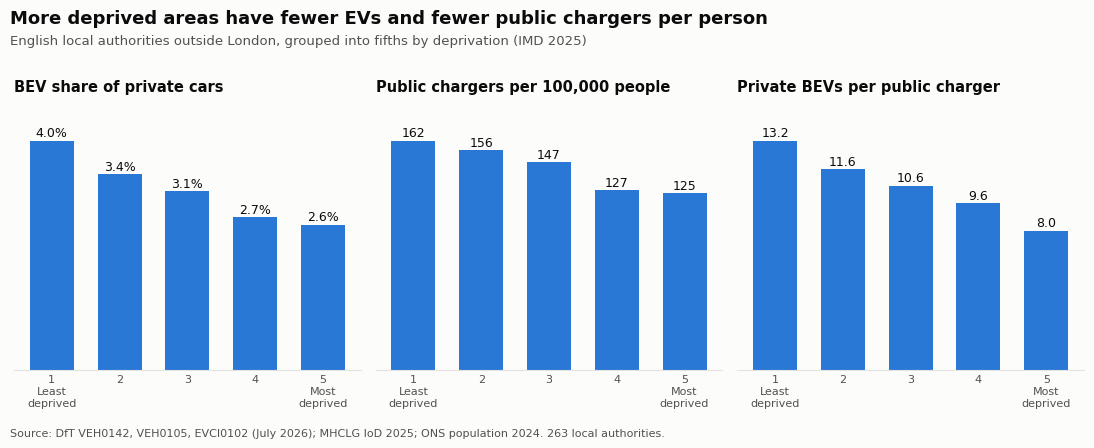

In [8]:
labels = ["1\nLeast\ndeprived", "2", "3", "4", "5\nMost\ndeprived"]
panels = [
    ("BEV share of private cars (%)", "BEV share of private cars", "{:.1f}%"),
    ("Chargers per 100k people", "Public chargers per 100,000 people", "{:.0f}"),
    ("Private BEVs per charger", "Private BEVs per public charger", "{:.1f}"),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 4.4))
for ax, (column, subtitle, fmt) in zip(axes, panels):
    values = groups_without_london[column]
    ax.bar(range(5), values, width=0.65, color=BLUE)
    for i, value in enumerate(values):
        ax.annotate(fmt.format(value), (i, value), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9, color=TEXT)
    ax.set_xticks(range(5))
    ax.set_xticklabels(labels, fontsize=8)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_yticks([])
    ax.grid(visible=False)
    ax.set_title(subtitle, fontsize=10.5)

fig.suptitle("More deprived areas have fewer EVs and fewer public chargers per person",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.text(0.01, 0.9, "English local authorities outside London, grouped into fifths by deprivation (IMD 2025)",
         fontsize=9.5, color=TEXT_2)
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
add_source(fig, "Source: DfT VEH0142, VEH0105, EVCI0102 (July 2026); MHCLG IoD 2025; ONS population 2024. 263 local authorities.")
fig.savefig(FIGURES + "09_deprivation_groups.png", dpi=200)
plt.show()

**How to read this chart:** three small charts with the same five groups on the horizontal axis, from least deprived (left) to most deprived (right).

**What it shows**
- **Left:** EV adoption falls steadily with deprivation, from 4.0% of private cars in the least deprived fifth to 2.6% in the most deprived fifth.
- **Middle:** public charging provision also falls, from about 160 to about 125 chargers per 100,000 people (roughly a fifth fewer).
- **Right:** but because EVs are even rarer in deprived areas, each charger there serves *fewer* EVs today (8 vs 13).

**Interpretation:** today's public network has, broadly, followed demand: it is busiest where EV owners already are. This is reasonable in the short term, but it creates a risk. Deprived areas have fewer chargers per person, and as EVs become cheaper (including on the used market), their residents will start switching. Many of them are likely to live without a driveway, so they will depend on public charging more than the early adopters did. Question 4 tests this with the census housing data.

With London included the picture is similar for adoption, but London lifts the charger numbers of the deprived groups (see the second table).

## Answer to question 3

- **EV adoption follows income.** Richer areas have a clearly higher share of battery electric private cars (correlation about 0.7). Northern Ireland is a separate case, with very low adoption at every income level.
- **Deprived areas are behind.** In England outside London, the battery electric share falls from 4.0% in the least deprived fifth of local authorities to 2.6% in the most deprived fifth (correlation about −0.75). London is the exception, with high adoption even in deprived boroughs.
- **Public charging has followed the early adopters.** Deprived areas have about a fifth fewer public chargers per person. They do not look short of chargers today only because they have few EVs yet.
- **Business implication:** investing only where the gap is largest today means investing in better-off areas. A forward-looking plan should also prepare deprived, dense areas where residents cannot charge at home. Question 4 brings these factors together into a priority list.